# 04 (annexe) — Autres mesures de température : TN50, TNSOL et stations voisines

**Question.** Dans `01_data`, l'indice $Z$ (minimum de TN sous abri à Chablis, 1er avril – 15 mai) discrimine mal les années de perte :
2016 et 2024 sont en perte avec $Z \approx -1{,}5$ °C, alors que 2022, 2012 et 2020 sont très froides sans perte.

**Hypothèse testée (H2) : la mesure ne représente pas ce que subissent les bourgeons.** Deux variantes :
1. la hauteur de mesure — TN sous abri (≈ 1,5 m) contre TN50 (50 cm) et TNSOL (10 cm), plus proches des bourgeons ;
2. le lieu — une autre station de l'Yonne aurait-elle mieux vu 2016 ?

**Critère de lecture.** Avec 12 années et 3 pertes, pas de corrélation ni de test : on regarde **le rang** des années de perte parmi les 12.
Un bon indice place 2016, 2021 et 2024 parmi les années les plus froides.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
RAW = ROOT / "data" / "raw"
PROC = ROOT / "data" / "processed"

CHABLIS = 89068001
DEBUT, FIN = 401, 515              # fenêtre : 1er avril – 15 mai (MMJJ)
N_JOURS = 45
MIN_JOURS_VALIDES = 40             # une année compte si ≥ 40 jours valides sur 45
VARIABLES = ["TN", "TN50", "TNSOL"]

In [2]:
# Chargement : toutes les stations de l'Yonne, fenêtre de risque uniquement
fichiers = [RAW / "Q_89_previous-1950-2024_RR-T-Vent.csv.gz",
            RAW / "Q_89_latest-2025-2026_RR-T-Vent.csv.gz"]
brut = pd.concat([pd.read_csv(f, sep=";", low_memory=False) for f in fichiers], ignore_index=True)
brut = brut.drop_duplicates(subset=["NUM_POSTE", "AAAAMMJJ"])

mmjj = brut["AAAAMMJJ"] % 10000
fen = brut[mmjj.between(DEBUT, FIN)].copy()
fen["annee"] = fen["AAAAMMJJ"] // 10000

# Codes qualité : on écarte 2 (douteuse), on garde 0, 1, 9
for v in VARIABLES:
    q = "Q" + v
    if q in fen.columns:
        fen.loc[fen[q] == 2, v] = np.nan
print("Colonnes qualité présentes :", [("Q" + v) for v in VARIABLES if ("Q" + v) in fen.columns])
print(f"{fen['NUM_POSTE'].nunique()} stations, {fen['annee'].min()}–{fen['annee'].max()}")
NOMS = fen.groupby("NUM_POSTE")["NOM_USUEL"].first()
def meta_nom(p):
    return NOMS.loc[p]

Colonnes qualité présentes : ['QTN', 'QTN50', 'QTNSOL']
87 stations, 1950–2026


In [3]:
def indice_annuel(df, variable):
    """Minimum annuel de `variable` dans la fenêtre, NaN si moins de MIN_JOURS_VALIDES jours valides."""
    g = df.groupby("annee")[variable]
    z = g.min()
    z[g.count() < MIN_JOURS_VALIDES] = np.nan
    return z

ch = fen[fen["NUM_POSTE"] == CHABLIS]
couverture = pd.DataFrame({v: ch.groupby("annee")[v].count() for v in VARIABLES})
print("Jours valides par année à Chablis (sur 45) — dernières années :")
print(couverture.loc[2009:].to_string())

indices_chablis = pd.DataFrame({f"Z_{v}": indice_annuel(ch, v) for v in VARIABLES})
print("\nAnnées complètes à Chablis :", indices_chablis.notna().sum().to_dict())

Jours valides par année à Chablis (sur 45) — dernières années :
       TN  TN50  TNSOL
annee                 
2009   45     0      0
2010   45     0      0
2011   45     0      0
2012   45     0      0
2013   45     0      0
2014   45     0      0
2015   45     0      0
2016   45     0      0
2017   45     0      0
2018   45     0      0
2019   45     0      0
2020   45     0      0
2021   45     0      0
2022   45     0      0
2023   45     0      0
2024   45     0      0
2025   45     0      0
2026   45     0      0

Années complètes à Chablis : {'Z_TN': 64, 'Z_TN50': 0, 'Z_TNSOL': 16}


In [ ]:
# Pertes : moyenne olympique des 5 années précédentes, seuil 20 %
SEUIL_PERTE = 0.20

def moyenne_olympique(fenetre):
    return (fenetre.sum() - fenetre.max() - fenetre.min()) / (len(fenetre) - 2)

yonne = pd.read_csv(PROC / "douanes_yonne_aop_2009_2025.csv")
pertes = (yonne[["annee", "rendement_aop_hl_ha"]].sort_values("annee")
          .rename(columns={"rendement_aop_hl_ha": "rendement"}).reset_index(drop=True))
pertes["reference"] = pertes["rendement"].rolling(5).apply(moyenne_olympique, raw=True).shift(1)
pertes["taux_perte"] = 1 - pertes["rendement"] / pertes["reference"]
pertes["perte"] = pertes["taux_perte"] >= SEUIL_PERTE
pertes = pertes.dropna(subset=["reference"]).reset_index(drop=True)
assert len(pertes) == 12, f"{len(pertes)} années au lieu de 12"
print("Années en perte :", pertes.loc[pertes["perte"], "annee"].tolist())

Années en perte : [2016, 2021, 2024]


In [5]:
def rangs_des_pertes(table, colonne):
    """Rang (1 = année la plus froide) de chaque année de perte, sur les années où l'indice existe."""
    t = table.dropna(subset=[colonne])
    rang = t[colonne].rank(method="min")
    return {int(a): int(r) for a, r in zip(t.loc[t["perte"], "annee"], rang[t["perte"]])}, len(t)

base = pertes.merge(indices_chablis.reset_index(), on="annee", how="left")
print(base[["annee", "taux_perte", "perte"] + [f"Z_{v}" for v in VARIABLES]]
      .round({"taux_perte": 2}).to_string(index=False))

print("\nRang des années de perte (1 = la plus froide) :")
for v in VARIABLES:
    r, n = rangs_des_pertes(base, f"Z_{v}")
    print(f"  Z_{v:<6} sur {n:>2} années : {r}")

 annee  taux_perte  perte  Z_TN  Z_TN50  Z_TNSOL
  2014       -0.07  False  -1.7     NaN      NaN
  2015       -0.07  False  -2.6     NaN      NaN
  2016        0.52   True  -1.5     NaN      NaN
  2017        0.11  False  -3.2     NaN      NaN
  2018       -0.41  False  -0.5     NaN      NaN
  2019        0.18  False  -3.4     NaN      NaN
  2020       -0.00  False  -4.2     NaN      NaN
  2021        0.39   True  -4.9     NaN      NaN
  2022       -0.31  False  -5.9     NaN      NaN
  2023       -0.29  False  -3.5     NaN      NaN
  2024        0.42   True  -1.5     NaN      NaN
  2025       -0.13  False  -2.2     NaN      NaN

Rang des années de perte (1 = la plus froide) :
  Z_TN     sur 12 années : {2016: 10, 2021: 2, 2024: 10}
  Z_TN50   sur  0 années : {}
  Z_TNSOL  sur  0 années : {}


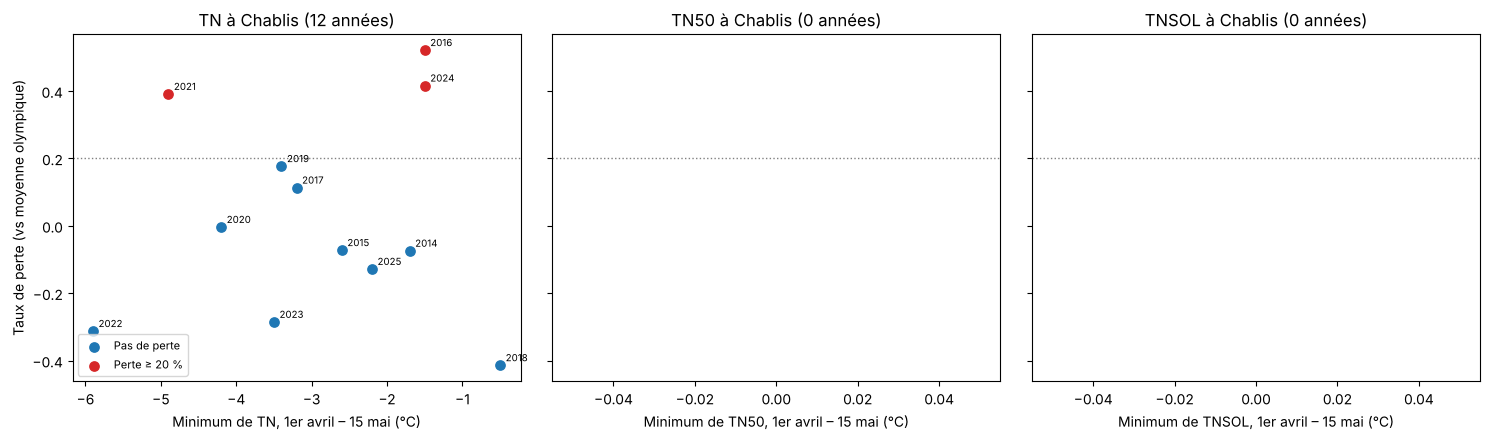

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, v in zip(axes, VARIABLES):
    col = f"Z_{v}"
    t = base.dropna(subset=[col])
    for est_perte, couleur, label in [(False, "tab:blue", "Pas de perte"), (True, "tab:red", "Perte ≥ 20 %")]:
        s = t[t["perte"] == est_perte]
        ax.scatter(s[col], s["taux_perte"], color=couleur, label=label, s=45)
    for _, l in t.iterrows():
        ax.annotate(int(l["annee"]), (l[col], l["taux_perte"]), textcoords="offset points", xytext=(4, 3), fontsize=7)
    ax.axhline(SEUIL_PERTE, color="grey", linestyle=":", linewidth=1)
    ax.set_title(f"{v} à Chablis ({len(t)} années)")
    ax.set_xlabel(f"Minimum de {v}, 1er avril – 15 mai (°C)")
axes[0].set_ylabel("Taux de perte (vs moyenne olympique)")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### TN50 et TNSOL : où sont-ils mesurés ?

À Chablis, TN50 n'existe pas et TNSOL s'arrête en 2008 : aucune des deux mesures ne couvre 2014–2025.
On cherche donc les stations de l'Yonne qui les mesurent sur la période, et on refait le classement.

In [7]:
for v in ["TN50", "TNSOL"]:
    n = fen[fen[v].notna() & fen["annee"].between(2014, 2025)].groupby("NUM_POSTE")["annee"].nunique()
    for p in n[n >= 9].index:
        d = fen[(fen["NUM_POSTE"] == p) & fen["annee"].between(2014, 2025)]
        z = indice_annuel(d, v).dropna()
        t = pertes.merge(z.rename("Z").reset_index(), on="annee")
        r, k = rangs_des_pertes(t, "Z")
        print(f"{v:<6} {meta_nom(p):<20} ({k:>2} années) rangs des pertes : {r}")

TN50   AUXERRE-PERRIGNY     (12 années) rangs des pertes : {2016: 11, 2021: 2, 2024: 8}
TNSOL  AUXERRE-PERRIGNY     (12 années) rangs des pertes : {2016: 12, 2021: 2, 2024: 9}
TNSOL  ST ANDRE             (10 années) rangs des pertes : {2016: 9, 2021: 1, 2024: 8}
TNSOL  SAINT PRIVE          ( 9 années) rangs des pertes : {2021: 3, 2024: 8}
TNSOL  SAVIGNY/CLAIRIS      ( 9 années) rangs des pertes : {2021: 2, 2024: 8}
TNSOL  TONNERRE JOUDRE      ( 9 années) rangs des pertes : {2021: 1, 2024: 7}


## Stations voisines de l'Yonne

On liste les stations qui mesurent TN, on calcule leur distance à Chablis, et on garde celles qui couvrent les 12 années 2014–2025.
Puis on refait le même classement des années de perte, station par station.

In [8]:
meta = (fen.groupby("NUM_POSTE")[["NOM_USUEL", "LAT", "LON", "ALTI"]].first())
lat0, lon0 = meta.loc[CHABLIS, ["LAT", "LON"]]
la1, lo1 = np.radians(lat0), np.radians(lon0)
la2, lo2 = np.radians(meta["LAT"]), np.radians(meta["LON"])
meta["dist_km"] = 6371 * 2 * np.arcsin(np.sqrt(np.sin((la2 - la1) / 2) ** 2
                                               + np.cos(la1) * np.cos(la2) * np.sin((lo2 - lo1) / 2) ** 2))

Z_TN = {p: indice_annuel(d, "TN") for p, d in fen.groupby("NUM_POSTE")}
Z_TN = pd.DataFrame(Z_TN)                       # lignes : années, colonnes : stations
annees = pertes["annee"].tolist()
complete = Z_TN.reindex(annees).notna().all()
meta["annees_TN_total"] = Z_TN.notna().sum()
meta["couvre_2014_2025"] = complete

voisines = meta[meta["couvre_2014_2025"]].sort_values("dist_km")
print(voisines[["NOM_USUEL", "ALTI", "dist_km", "annees_TN_total"]].round(1).head(15).to_string())

                  NOM_USUEL  ALTI  dist_km  annees_TN_total
NUM_POSTE                                                  
89068001       CHABLIS_SAPC   141      0.0               64
89418007    TONNERRE JOUDRE   200     16.1               22
89295001   AUXERRE-PERRIGNY   152     18.0               13
89279002        NOYERS_SAPC   266     19.5               16
89131001         CRUZY_SAPC   291     32.5               63
89003001            AILLANT   124     33.2               44
89260001      MOLESMES_SAPC   355     34.0               46
89333001           ST ANDRE   300     42.2               21
89192001    GRANDCHAMP_SAPC   180     45.2               46
89133001         CUDOT_SAPC   170     49.2               19
89387002               SENS    70     53.6               71
89273001    ST FARGEAU_SAPC   258     53.8               54
89380001    SAVIGNY/CLAIRIS   184     59.0               63
89365001        SAINT PRIVE   198     63.0               21


In [9]:
N_VOISINES = 8
choix = voisines.head(N_VOISINES + 1).index        # Chablis + 8 plus proches
tab = Z_TN.reindex(annees)[choix].copy()
tab.columns = [f"{meta.loc[p, 'NOM_USUEL']} ({meta.loc[p, 'ALTI']:.0f} m, {meta.loc[p, 'dist_km']:.0f} km)" for p in choix]
tab.insert(0, "perte", pertes.set_index("annee")["perte"])
print(tab.round(1).to_string())

print("\nRang des années de perte (1 = la plus froide sur 12) :")
for p in choix:
    t = pertes.assign(Z=Z_TN.reindex(annees)[p].values)
    r, n = rangs_des_pertes(t, "Z")
    print(f"  {meta.loc[p, 'NOM_USUEL']:<28} {r}")

# Indice « réseau » : minimum sur les stations retenues
t = pertes.assign(Z=Z_TN.reindex(annees)[choix].min(axis=1).values)
print(f"  {'MIN DES STATIONS RETENUES':<28} {rangs_des_pertes(t, 'Z')[0]}")

       perte  CHABLIS_SAPC (141 m, 0 km)  TONNERRE JOUDRE (200 m, 16 km)  AUXERRE-PERRIGNY (152 m, 18 km)  NOYERS_SAPC (266 m, 19 km)  CRUZY_SAPC (291 m, 33 km)  AILLANT (124 m, 33 km)  MOLESMES_SAPC (355 m, 34 km)  ST ANDRE (300 m, 42 km)  GRANDCHAMP_SAPC (180 m, 45 km)
annee                                                                                                                                                                                                                                                                          
2014   False                        -1.7                             0.0                              0.3                         0.8                        0.4                    -2.5                           1.6                     -0.8                             0.0
2015   False                        -2.6                            -1.2                             -2.0                        -0.6                       -0.6                    -3.5

In [10]:
# Zoom sur 2016 : TN quotidienne fin avril – mi-mai sur les stations retenues
z16 = fen[(fen["annee"] == 2016) & fen["NUM_POSTE"].isin(choix) & (fen["AAAAMMJJ"] % 10000).between(415, 515)]
piv = z16.pivot_table(index="AAAAMMJJ", columns="NUM_POSTE", values="TN")[list(choix)]
piv.columns = [meta.loc[p, "NOM_USUEL"] for p in choix]
print(piv.round(1).to_string())

          CHABLIS_SAPC  TONNERRE JOUDRE  AUXERRE-PERRIGNY  NOYERS_SAPC  CRUZY_SAPC  AILLANT  MOLESMES_SAPC  ST ANDRE  GRANDCHAMP_SAPC
AAAAMMJJ                                                                                                                             
20160415           9.8              9.6               9.9          9.0         8.7      8.1            8.5       8.9              9.3
20160416           9.4              9.1               9.3          8.2         8.2      8.9            7.8       8.1              9.0
20160417           6.7              5.6               6.7          6.0         5.5      6.0            5.2       6.0              6.1
20160418           3.1              2.8               3.1          1.3         1.1      1.5            2.4       2.3              1.9
20160419          -1.5             -0.7               0.0          1.5         1.0     -2.0            5.5      -1.2             -0.6
20160420           3.7              5.8               4.7     

## Conclusions

**1. TN50 et TNSOL ne sont pas disponibles à Chablis sur la période utile.** TN50 n'y a jamais été mesuré, TNSOL seulement de 1993 à 2008.
Là où ces mesures existent (Auxerre-Perrigny, Saint-André, Tonnerre, Saint-Privé, Savigny-sur-Clairis), elles ne changent pas le classement : 2021 ressort parmi les années les plus froides,
2016 et 2024 restent parmi les plus douces. **Mesurer plus près du sol ne résout pas le problème.**

**2. Aucune station voisine ne « voit » 2016 et 2024.** Sur les 9 stations retenues (jusqu'à 45 km), le minimum 2016 est compris entre −2,0 et 0,0 °C,
celui de 2024 entre −1,9 et +0,2 °C. Le minimum du réseau n'aide pas non plus. **H2 (station mal placée) n'explique donc pas ces deux années.**

**3. Chablis est l'une des stations les plus froides du réseau** les années de gel (2022 : −5,9 °C contre −2,4 à −5,7 ailleurs) :
cohérent avec un effet de fond de vallée, qui augmente la fréquence de déclenchement par rapport aux coteaux.

**4. Lecture des deux années manquées : 2016 et 2024 combinent gel modéré sous abri et grêle.**
- **2024** : pertes mixtes. Gelées du 15 au 25 avril dans le Chablisien, avec des dégâts localisés « très concrets par endroits » (Agri Bourgogne, 17/05/2024), puis grêle du 1er mai (environ 1 000 ha touchés dont 400 à plus de 80 % selon le BIVB, cité par Réussir ; environ 2 000 ha dans l'Yonne selon la DRAAF) et mildiou. À Chablis, le minimum sous abri est de −1,5 °C le 24 avril, et aucune station voisine ne descend sous −1,9 °C. La part du gel dans la perte n'est pas quantifiable avec ces sources.
- **2016** : gel réel fin avril (vignoble touché d'après la presse), mais modéré sous abri, −1,5 °C à Chablis au plus froid (19 avril), et aucune des 9 stations sous −2 °C.
  Dans les deux cas, un gel faible sous abri a été suivi de dégâts — ce qui renvoie à la **sensibilité de la vigne selon son stade** (H3b), pas au lieu de mesure.

**Conséquence pour le contrat.** Le défaut de l'indice tient à sa conception — un seuil de température fixe sur une fenêtre fixe —
plus qu'à la station choisie. Un indice qui intègre le stade de la vigne (débourrement estimé par la chaleur accumulée) est la piste d'amélioration ;
il n'est pas calibrable de façon fiable sur 12 années.